Please upload your 'task2_train.csv' file:


Saving task2_train.csv to task2_train.csv
Dataset Loaded Successfully! Shape: (3207, 12)

Training model...

     MODEL PERFORMANCE        
Mean Absolute Error (MAE): $12,254.10
Root Mean Squared Error (RMSE): $31,253.67
R² Score: 0.6215



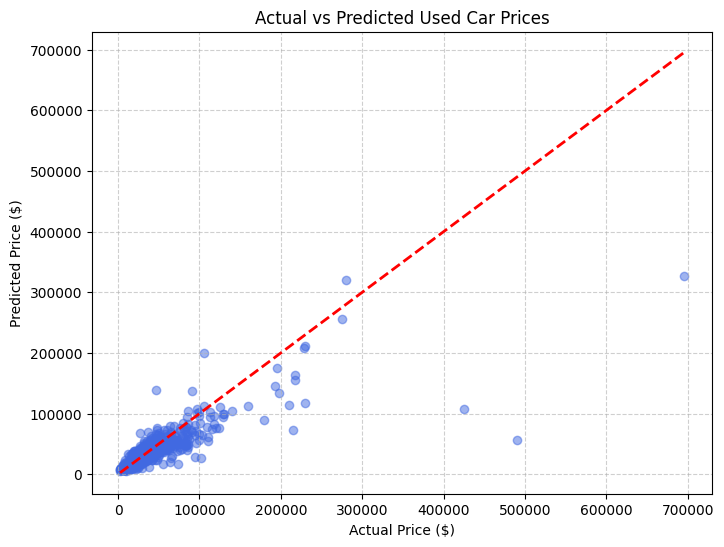

In [16]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from google.colab import files

#  LOAD DATASET
print("Please upload your 'task2_train.csv' file:")
uploaded = files.upload()
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)
print(f"Dataset Loaded Successfully! Shape: {df.shape}")

#  DATA CLEANING & PREPROCESSING
# Clean price and milage columns
df['price'] = df['price'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False).astype(float)
df['milage'] = df['milage'].astype(str).str.replace('mi.', '', regex=False).str.replace(',', '', regex=False).str.strip().astype(float)

# Separate features and target
X = df.drop(columns=['price'])
y = df['price']

# Train-validation split (80% / 20%)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

#  BUILD PIPELINE & MODEL
numerical_cols = ['model_year', 'milage']
categorical_cols = ['brand', 'model', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ])

model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', model)
])

# TRAIN & EVALUATE MODEL
print("\nTraining model...")
pipeline.fit(X_train, y_train)
preds = pipeline.predict(X_val)

mae = mean_absolute_error(y_val, preds)
rmse = np.sqrt(mean_squared_error(y_val, preds))
r2 = r2_score(y_val, preds)

print("\n==============================")
print("     MODEL PERFORMANCE        ")
print("==============================")
print(f"Mean Absolute Error (MAE): ${mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:,.2f}")
print(f"R² Score: {r2:.4f}")
print("==============================\n")

# 5. VISUALIZATION
plt.figure(figsize=(8, 6))
plt.scatter(y_val, preds, alpha=0.5, color='royalblue')
plt.plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], '--r', linewidth=2)
plt.xlabel('Actual Price ($)')
plt.ylabel('Predicted Price ($)')
plt.title('Actual vs Predicted Used Car Prices')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()